
# Fashion-MNIST: CNN Training & Error Analysis

## Objective
Build and evaluate a Convolutional Neural Network (CNN)
to classify grayscale images of clothing into 10 categories.

## Workflow
1. Load and explore the dataset
2. Preprocess and split the data
3. Define a CNN architecture
4. Train and validate the model
5. Evaluate performance on unseen test data
6. Analyze classification errors
7. Identify potential improvements

**Framework:** PyTorch  
**Dataset:** Fashion-MNIST  
**Task:** Multiclass Image Classification


In [4]:

import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [5]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

classes = train_data.classes

print(f"Training samples: {len(train_data):,}")
print(f"Test samples: {len(test_data):,}")
print(f"Classes: {classes}")


100%|██████████| 26.4M/26.4M [00:36<00:00, 716kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 663kB/s]
100%|██████████| 4.42M/4.42M [00:06<00:00, 692kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.26MB/s]

Training samples: 60,000
Test samples: 10,000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


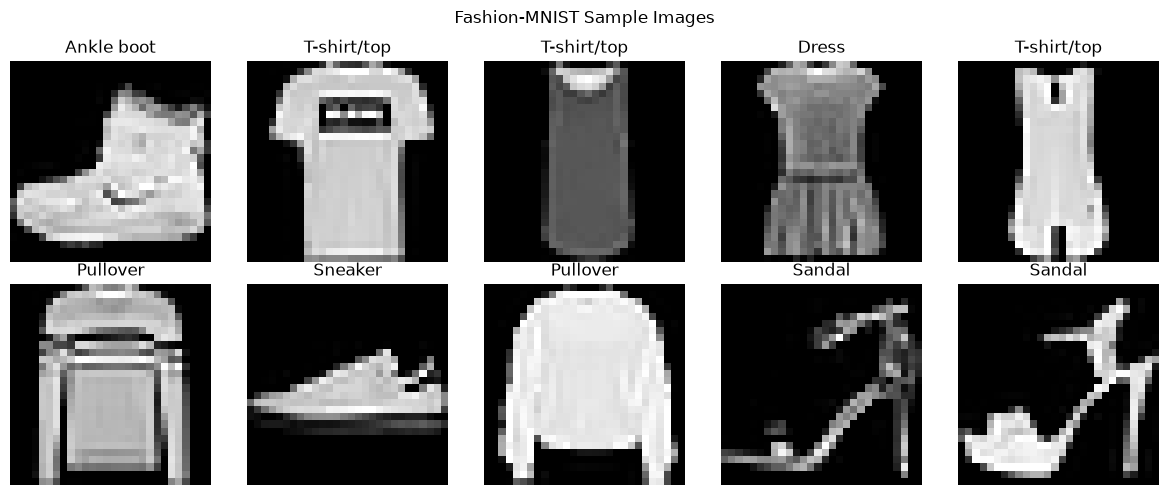

In [6]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()



## Data Preparation

The original training dataset contains 60,000 labeled images.

We split it into:
- **Training:** 50,000 images
- **Validation:** 10,000 images

The official test set contains 10,000 additional images.

The validation set is used to monitor model performance
during training. The test set is reserved for final evaluation.

Images are normalized before being passed to the CNN.


In [7]:

train_set, val_set = random_split(
    train_data,
    [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_set, batch_size=128, shuffle=True
)
val_loader = DataLoader(
    val_set, batch_size=128
)
test_loader = DataLoader(
    test_data, batch_size=128
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 391
Validation batches: 79
Test batches: 79


In [8]:

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = FashionCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)


FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [9]:

def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_state = None

for epoch in range(5):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Train Acc: {train_acc:.3f} | "
        f"Val Acc: {val_acc:.3f} | "
        f"Val Loss: {val_loss:.3f}"
    )

model.load_state_dict(best_state)
model.to(device)


Epoch 1/5 | Train Acc: 0.795 | Val Acc: 0.867 | Val Loss: 0.364
Epoch 2/5 | Train Acc: 0.871 | Val Acc: 0.888 | Val Loss: 0.308
Epoch 3/5 | Train Acc: 0.889 | Val Acc: 0.899 | Val Loss: 0.286
Epoch 4/5 | Train Acc: 0.902 | Val Acc: 0.905 | Val Loss: 0.260
Epoch 5/5 | Train Acc: 0.910 | Val Acc: 0.914 | Val Loss: 0.240


FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

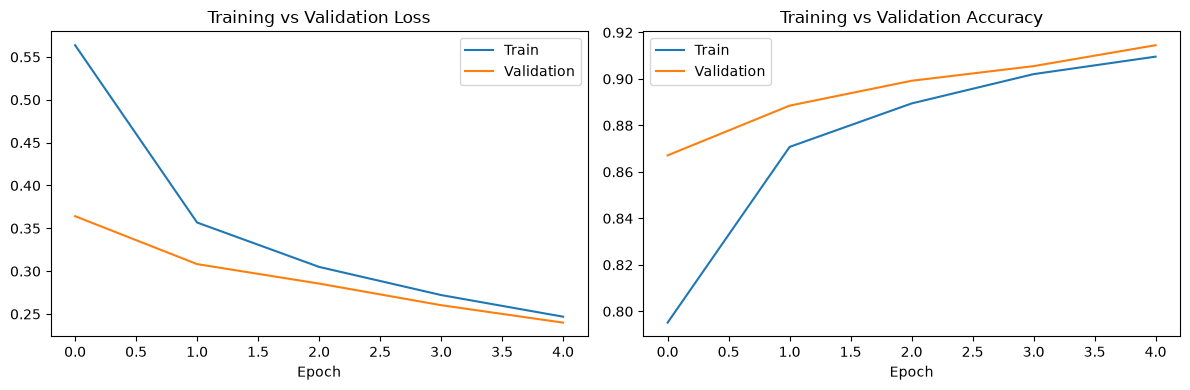

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [11]:

model.eval()

y_true = []
y_pred = []
mistakes = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

        for image, actual, predicted in zip(
            images, labels, predictions
        ):
            if actual.item() != predicted.item():
                mistakes.append((
                    image.squeeze().numpy(),
                    actual.item(),
                    predicted.item()
                ))

print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    zero_division=0
))


              precision    recall  f1-score   support

 T-shirt/top       0.86      0.85      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.84      0.86      0.85      1000
       Dress       0.91      0.90      0.91      1000
        Coat       0.87      0.81      0.84      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.70      0.77      0.73      1000
     Sneaker       0.93      0.98      0.96      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.98      0.95      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



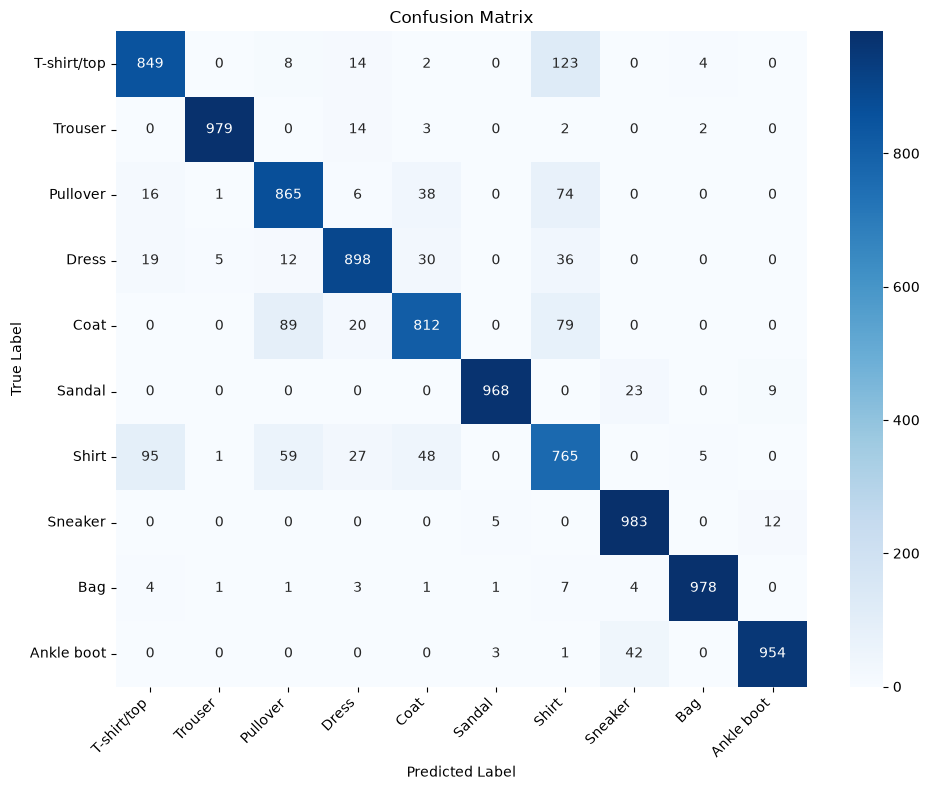

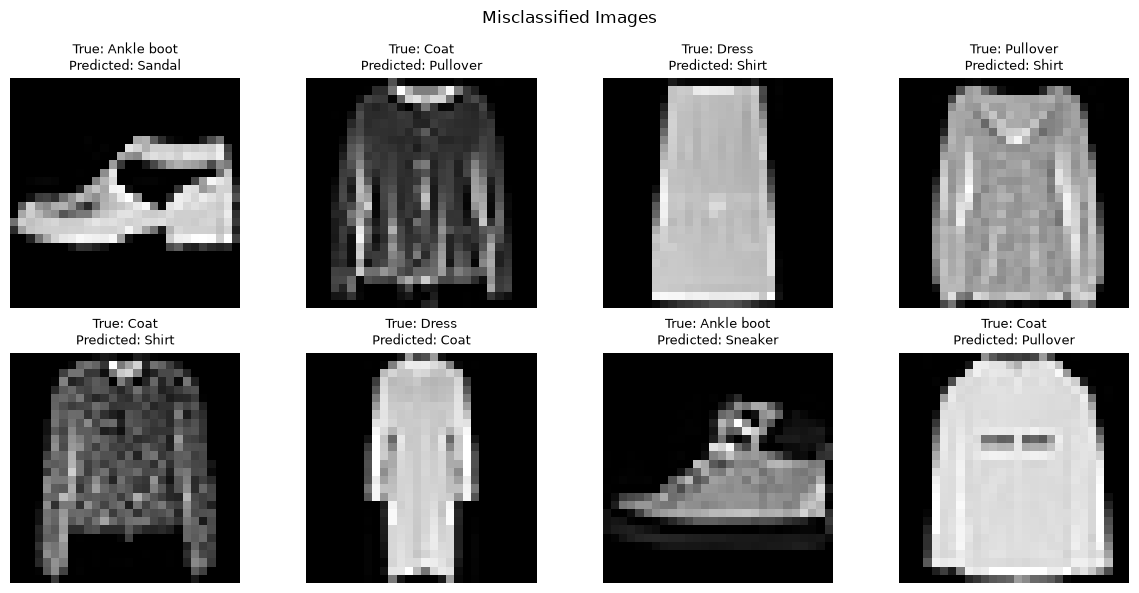

In [12]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (image, actual, predicted) in zip(
    axes.flat, mistakes[:8]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {classes[actual]}\n"
        f"Predicted: {classes[predicted]}",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("Misclassified Images")
plt.tight_layout()
plt.show()



## Baseline Model — Results Analysis

The CNN achieved **91% test accuracy** on 10,000 unseen images.

### Key Findings
- Strong performance on Trouser (F1: 0.99), Bag (0.98),
  and Sandal (0.98).
- Shirt was the most challenging category, with an
  F1-score of 0.73 and precision of 0.70.
- Coat and Pullover also showed lower performance
  compared with more visually distinct categories.

### Hypothesis
Visually similar clothing categories may be harder
for the CNN to distinguish using low-resolution images.

### Next Experiment
Evaluate whether data augmentation improves
generalization and classification performance,
particularly for Shirt, Coat, and Pullover.



## Experiment 2 — Data Augmentation

### Research Question
Can data augmentation improve the CNN's generalization
and reduce classification errors between visually
similar clothing categories?

### Hypothesis
Small random rotations and translations during training
may help the model learn more robust visual features.

### Experimental Setup
- Same CNN architecture
- Same training and validation split
- Same optimizer, learning rate, batch size and epochs
- Data augmentation applied only to training images
- Original test set preserved for final evaluation

### Evaluation
Compare overall accuracy and per-class F1-scores,
especially for Shirt, Coat and Pullover.


In [14]:

from torch.utils.data import Subset

# Augmentation is applied to training images only.
augmented_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=10,
        translate=(0.08, 0.08)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

augmented_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=augmented_transform
)

# Reuse the exact same training indices.
augmented_train_set = Subset(
    augmented_data,
    train_set.indices
)

augmented_train_loader = DataLoader(
    augmented_train_set,
    batch_size=128,
    shuffle=True
)

print("Augmented training samples:",
      len(augmented_train_set))
print("Validation samples:", len(val_set))


Augmented training samples: 50000
Validation samples: 10000


In [15]:

# Keep the original model unchanged.
aug_model = FashionCNN().to(device)

aug_optimizer = torch.optim.Adam(
    aug_model.parameters(),
    lr=0.001
)

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def evaluate_model(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


aug_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_aug_loss = float("inf")
best_aug_state = None

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(
        aug_model,
        augmented_train_loader,
        aug_optimizer
    )

    val_loss, val_acc = evaluate_model(
        aug_model,
        val_loader
    )

    aug_history["train_loss"].append(train_loss)
    aug_history["val_loss"].append(val_loss)
    aug_history["train_acc"].append(train_acc)
    aug_history["val_acc"].append(val_acc)

    if val_loss < best_aug_loss:
        best_aug_loss = val_loss
        best_aug_state = {
            k: v.detach().cpu().clone()
            for k, v in aug_model.state_dict().items()
        }

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Acc: {train_acc:.3f} | "
        f"Val Acc: {val_acc:.3f} | "
        f"Val Loss: {val_loss:.3f}"
    )

aug_model.load_state_dict(best_aug_state)
aug_model.to(device)


Epoch 1/5 | Train Acc: 0.722 | Val Acc: 0.828 | Val Loss: 0.459
Epoch 2/5 | Train Acc: 0.811 | Val Acc: 0.855 | Val Loss: 0.399
Epoch 3/5 | Train Acc: 0.835 | Val Acc: 0.871 | Val Loss: 0.356
Epoch 4/5 | Train Acc: 0.853 | Val Acc: 0.883 | Val Loss: 0.319
Epoch 5/5 | Train Acc: 0.861 | Val Acc: 0.892 | Val Loss: 0.296


FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [16]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

aug_model.eval()
aug_predictions = []
aug_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = aug_model(images.to(device))
        predictions = outputs.argmax(1).cpu()

        aug_predictions.extend(predictions.tolist())
        aug_labels.extend(labels.tolist())

baseline_accuracy = accuracy_score(y_true, y_pred)
aug_accuracy = accuracy_score(aug_labels, aug_predictions)

baseline_f1 = f1_score(
    y_true, y_pred, average=None
)

aug_f1 = f1_score(
    aug_labels, aug_predictions, average=None
)

comparison = pd.DataFrame({
    "Class": classes,
    "Baseline F1": baseline_f1,
    "Augmented F1": aug_f1
})

comparison["Difference"] = (
    comparison["Augmented F1"]
    - comparison["Baseline F1"]
)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Augmented Accuracy: {aug_accuracy:.4f}")
print(f"Difference: {aug_accuracy - baseline_accuracy:+.4f}")

display(comparison.round(4))


Baseline Accuracy: 0.9051
Augmented Accuracy: 0.8881
Difference: -0.0170


,Class,Baseline F1,Augmented F1,Difference
0,T-shirt/top,0.8563,0.8398,-0.0165
1,Trouser,0.9854,0.9800,-0.0054
2,Pullover,0.8505,0.8276,-0.0229
3,Dress,0.9062,0.8895,-0.0167
4,Coat,0.8397,0.8113,-0.0284
5,Sandal,0.9793,0.9768,-0.0024
6,Shirt,0.7331,0.6497,-0.0834
7,Sneaker,0.9581,0.9518,-0.0063
8,Bag,0.9834,0.9754,-0.0080
9,Ankle boot,0.9661,0.9607,-0.0054


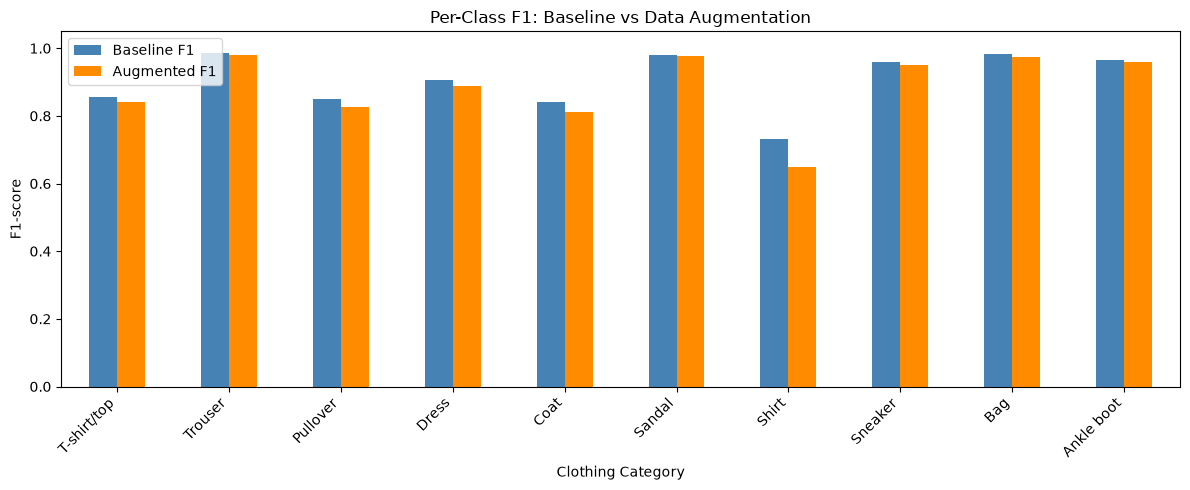

In [17]:

comparison_plot = comparison.set_index("Class")[
    ["Baseline F1", "Augmented F1"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Per-Class F1: Baseline vs Data Augmentation")
plt.ylabel("F1-score")
plt.xlabel("Clothing Category")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()



## Experiment 3 — Reduced Augmentation

### Observation
The first augmentation experiment reduced overall test
accuracy by approximately 1.7 percentage points.

The largest F1-score decline was observed for Shirt:
0.7331 → 0.6497.

### Hypothesis
The applied geometric transformations may have been
too strong for low-resolution Fashion-MNIST images.

### Next Step
Reduce the rotation and translation ranges while
keeping the model architecture and training setup
unchanged.

### Important Limitation
Single-run results may also be affected by random
initialization and training variability.


In [18]:

mild_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=5,
        translate=(0.03, 0.03)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

mild_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=mild_transform
)

mild_train_set = Subset(
    mild_data,
    train_set.indices
)

mild_train_loader = DataLoader(
    mild_train_set,
    batch_size=128,
    shuffle=True
)

print("Mild augmentation dataset ready")


Mild augmentation dataset ready


In [19]:

# Experiment 3: Mild Data Augmentation

# Reset the seed for a more controlled comparison
torch.manual_seed(SEED)

# Create a fresh model
mild_model = FashionCNN().to(device)

mild_optimizer = torch.optim.Adam(
    mild_model.parameters(),
    lr=0.001
)

mild_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_mild_loss = float("inf")
best_mild_state = None

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(
        mild_model,
        mild_train_loader,
        mild_optimizer
    )

    val_loss, val_acc = evaluate_model(
        mild_model,
        val_loader
    )

    mild_history["train_loss"].append(train_loss)
    mild_history["val_loss"].append(val_loss)
    mild_history["train_acc"].append(train_acc)
    mild_history["val_acc"].append(val_acc)

    if val_loss < best_mild_loss:
        best_mild_loss = val_loss
        best_mild_state = {
            k: v.detach().cpu().clone()
            for k, v in mild_model.state_dict().items()
        }

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Acc: {train_acc:.3f} | "
        f"Val Acc: {val_acc:.3f} | "
        f"Val Loss: {val_loss:.3f}"
    )

mild_model.load_state_dict(best_mild_state)
mild_model.to(device)

print("Mild augmentation training complete!")


Epoch 1/5 | Train Acc: 0.768 | Val Acc: 0.858 | Val Loss: 0.397
Epoch 2/5 | Train Acc: 0.848 | Val Acc: 0.882 | Val Loss: 0.329
Epoch 3/5 | Train Acc: 0.868 | Val Acc: 0.891 | Val Loss: 0.296
Epoch 4/5 | Train Acc: 0.877 | Val Acc: 0.897 | Val Loss: 0.276
Epoch 5/5 | Train Acc: 0.889 | Val Acc: 0.904 | Val Loss: 0.260
Mild augmentation training complete!


In [20]:

# Evaluate the mild augmentation model
mild_model.eval()

mild_predictions = []
mild_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = mild_model(images.to(device))
        predictions = outputs.argmax(1).cpu()

        mild_predictions.extend(predictions.tolist())
        mild_labels.extend(labels.tolist())

mild_accuracy = accuracy_score(
    mild_labels, mild_predictions
)

mild_f1 = f1_score(
    mild_labels,
    mild_predictions,
    average=None
)

# Compare all three experiments
final_comparison = pd.DataFrame({
    "Class": classes,
    "Baseline": baseline_f1,
    "Strong Augmentation": aug_f1,
    "Mild Augmentation": mild_f1
})

print("=== Overall Test Accuracy ===")
print(f"Baseline:             {baseline_accuracy:.4f}")
print(f"Strong Augmentation:  {aug_accuracy:.4f}")
print(f"Mild Augmentation:    {mild_accuracy:.4f}")

print("\n=== Per-Class F1 Comparison ===")
display(final_comparison.round(4))


=== Overall Test Accuracy ===
Baseline:             0.9051
Strong Augmentation:  0.8881
Mild Augmentation:    0.9004

=== Per-Class F1 Comparison ===


,Class,Baseline,Strong Augmentation,Mild Augmentation
0,T-shirt/top,0.8563,0.8398,0.8498
1,Trouser,0.9854,0.9800,0.9849
2,Pullover,0.8505,0.8276,0.8538
3,Dress,0.9062,0.8895,0.9014
4,Coat,0.8397,0.8113,0.8380
5,Sandal,0.9793,0.9768,0.9772
6,Shirt,0.7331,0.6497,0.6998
7,Sneaker,0.9581,0.9518,0.9499
8,Bag,0.9834,0.9754,0.9756
9,Ankle boot,0.9661,0.9607,0.9606


## Experiment 3 — Mild Augmentation Results

Reducing the augmentation strength improved performance
compared with the stronger augmentation strategy.

### Overall Accuracy
- Baseline: **90.51%**
- Strong Augmentation: **88.81%**
- Mild Augmentation: **90.04%**

Mild augmentation recovered most of the performance lost
in the stronger augmentation experiment, but it did not
outperform the baseline model.

### Per-Class Observation
Pullover showed a small F1 improvement:
- Baseline: 0.8505
- Mild Augmentation: 0.8538

However, Shirt remained challenging:
- Baseline: 0.7331
- Mild Augmentation: 0.6998

### Conclusion
For this model and dataset, the baseline training setup
performed best overall.

The results suggest that augmentation strength has a
significant effect on performance, but additional
experiments are needed before concluding whether
augmentation is beneficial.

Possible next steps include:
- training for more epochs,
- testing different augmentation types,
- repeating experiments with multiple random seeds,
- or evaluating a stronger model architecture.